<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 11: CNN for Image Classification
Google Colab-ready code — uses CIFAR-10 as the substitute dataset. Run the following cells in order.

Task 1 — Load, Resize, Normalize and Split the Dataset

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 950s 6us/step
Training Images: (4000, 32, 32, 3)
Validation Images: (1000, 32, 32, 3)
Testing Images: (1000, 32, 32, 3)


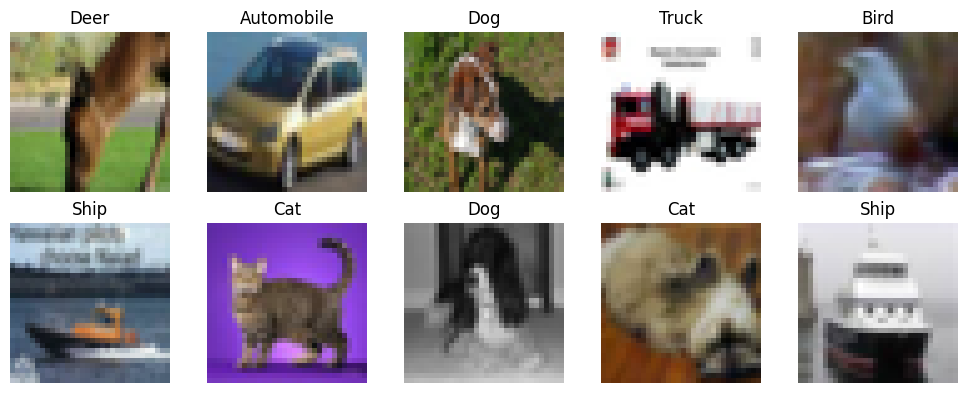

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load CIFAR-10 (cached after first download)
(x_train_full, y_train_full), (x_test_full, y_test_full) = cifar10.load_data()

class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Use a small subset for faster execution
rng = np.random.default_rng(42)

train_indices = rng.permutation(len(x_train_full))[:5000]
test_indices = rng.permutation(len(x_test_full))[:1000]

x_subset = x_train_full[train_indices]
y_subset = y_train_full[train_indices]

# Split into training and validation
x_train = x_subset[:4000]
y_train = y_subset[:4000]

x_val = x_subset[4000:]
y_val = y_subset[4000:]

x_test = x_test_full[test_indices]
y_test = y_test_full[test_indices]

# Normalize images
x_train = x_train.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_val = to_categorical(y_val, 10)
y_test = to_categorical(y_test, 10)

print("Training Images:", x_train.shape)
print("Validation Images:", x_val.shape)
print("Testing Images:", x_test.shape)

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[np.argmax(y_train[i])])
    plt.axis('off')

plt.tight_layout()
plt.show()

Task 2 — Build a CNN Model

In [3]:
# Build CNN model
model = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu',
                  name='first_conv'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten layer
    layers.Flatten(),

    # Fully connected layers
    layers.Dense(64, activation='relu'),

    # Output layer
    layers.Dense(10, activation='softmax')
])

# Compile CNN
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ first_conv (Conv2D)             │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Task 3 — Train the CNN and Plot Accuracy and Loss Curves

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 117ms/step - accuracy: 0.1675 - loss: 2.2344 - val_accuracy: 0.2260 - val_loss: 2.0866
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.3050 - loss: 1.8910 - val_accuracy: 0.3380 - val_loss: 1.7606
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.3820 - loss: 1.6737 - val_accuracy: 0.4070 - val_loss: 1.6166
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step - accuracy: 0.4280 - loss: 1.5877 - val_accuracy: 0.3940 - val_loss: 1.6371
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - accuracy: 0.4675 - loss: 1.4910 - val_accuracy: 0.4360 - val_loss: 1.5168
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 87ms/step - accuracy: 0.5005 - loss: 1.3826 - val_accuracy: 0.4730 - val_loss: 1.4489
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step - accuracy: 0.5300 - loss: 1.3161 - val_accuracy: 0.4550 - val_loss: 1.5057
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - accuracy: 0.5487 - loss: 1.2621 - val_accuracy: 0.474

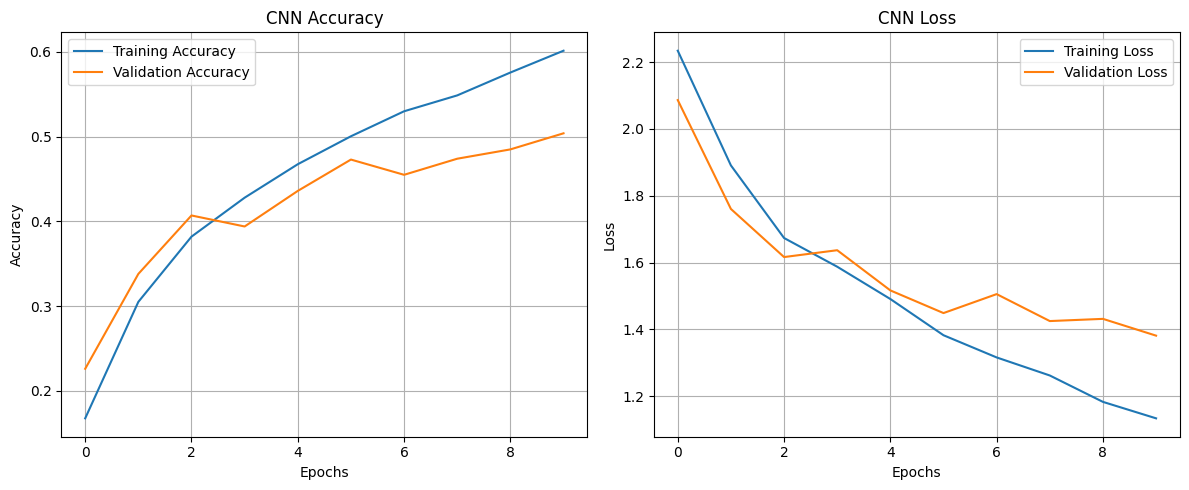

Test Accuracy: 53.40%
Test Loss: 1.3372


In [4]:
# Train CNN model
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    verbose=1
)

# Plot accuracy and loss
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('CNN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Evaluate model
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Task 4 — Confusion Matrix and Sample Misclassifications

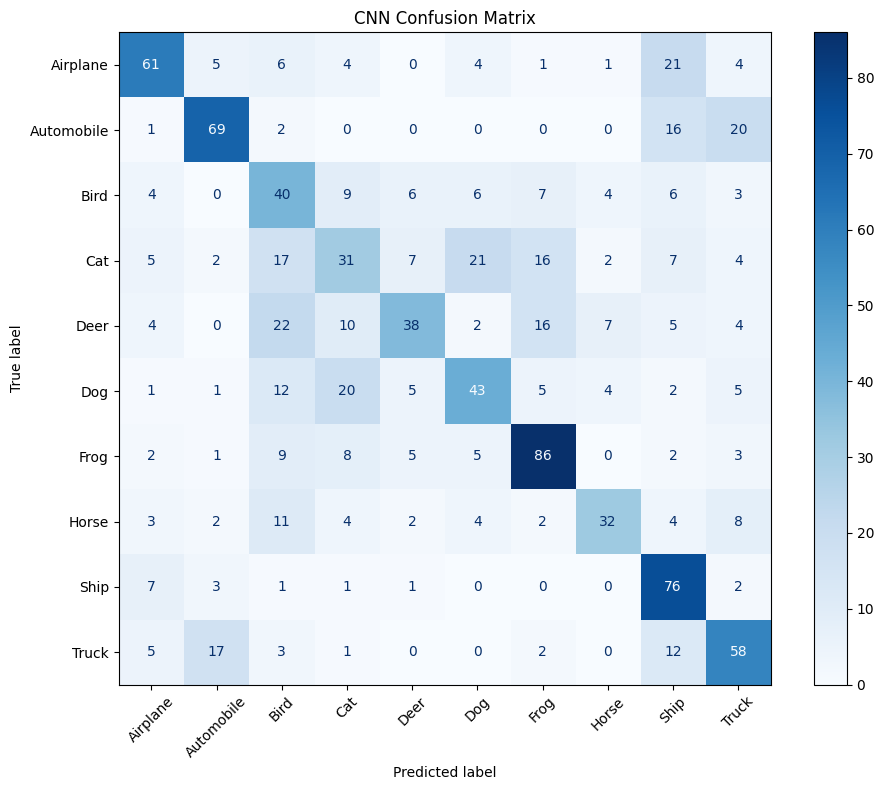

Total Misclassified Images: 466


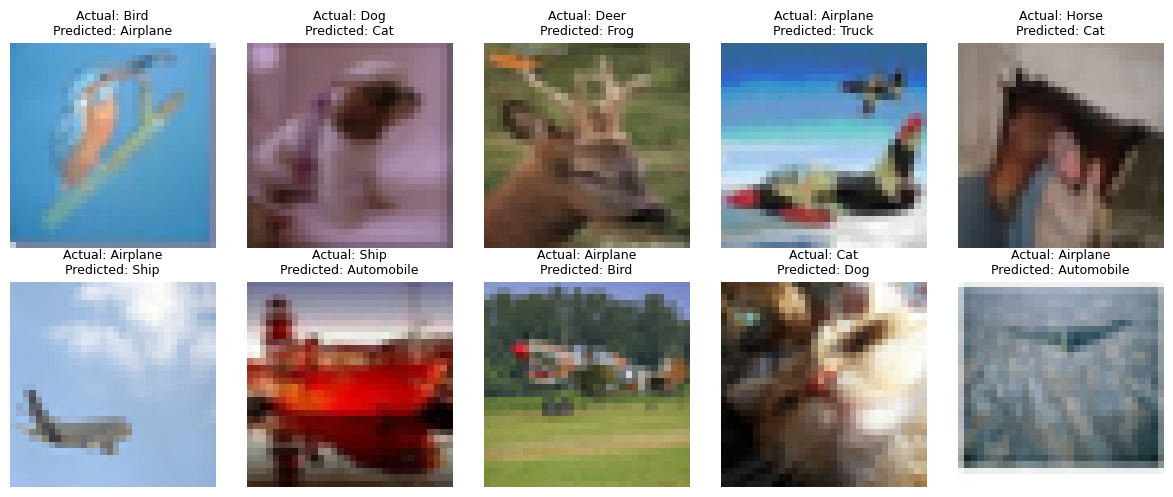

In [5]:
# Predict test images
y_pred_probs = model.predict(x_test, verbose=0)

# Convert probabilities to class labels
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45,
    values_format='d'
)

plt.title('CNN Confusion Matrix')
plt.tight_layout()
plt.show()

# Find misclassified images
misclassified_indices = np.where(
    y_pred != y_true
)[0]

print("Total Misclassified Images:",
      len(misclassified_indices))

# Display up to 10 misclassified images
num_samples = min(10, len(misclassified_indices))

if num_samples > 0:
    plt.figure(figsize=(12, 5))

    for i in range(num_samples):
        idx = misclassified_indices[i]

        plt.subplot(2, 5, i + 1)
        plt.imshow(x_test[idx])

        plt.title(
            f"Actual: {class_names[y_true[idx]]}\n"
            f"Predicted: {class_names[y_pred[idx]]}",
            fontsize=9
        )

        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images found.")

Task 5 — Visualize Feature Maps of the First Convolution Layer

Feature Map Shape: (1, 30, 30, 32)


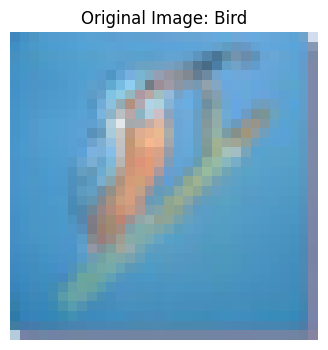

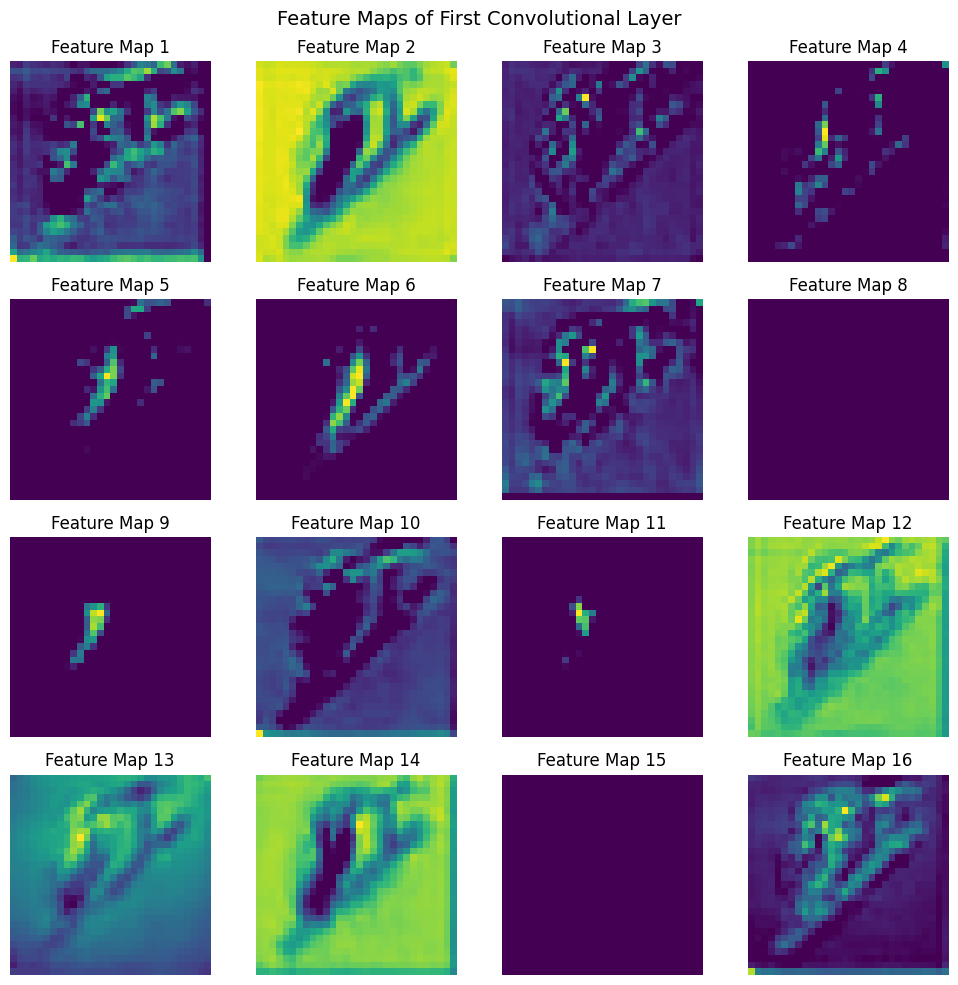

In [6]:
# Select first convolution layer
first_conv_layer = model.get_layer('first_conv')

# Create feature extraction model
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=first_conv_layer.output
)

# Select a sample test image
sample_image = x_test[0]

# Add batch dimension
input_image = np.expand_dims(sample_image, axis=0)

# Extract feature maps
feature_maps = feature_model.predict(
    input_image, verbose=0
)

print("Feature Map Shape:", feature_maps.shape)

# Display original image
plt.figure(figsize=(4, 4))
plt.imshow(sample_image)
plt.title(
    f"Original Image: {class_names[np.argmax(y_test[0])]}"
)
plt.axis('off')
plt.show()

# Display first 16 feature maps
num_feature_maps = min(16, feature_maps.shape[-1])

plt.figure(figsize=(10, 10))

for i in range(num_feature_maps):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        feature_maps[0, :, :, i],
        cmap='viridis'
    )

    plt.title(f'Feature Map {i + 1}')
    plt.axis('off')

plt.suptitle(
    'Feature Maps of First Convolutional Layer',
    fontsize=14
)

plt.tight_layout()
plt.show()